# Reproduction: Sami et al., *Early Results of an AI Multiagent System for Requirements Elicitation and Analysis* (PROFES 2024)

LNCS, Springer, 2025, pp. 307–316, doi:10.1007/978-3-031-78386-9_20 — base paper.

**What is reproduced:** the four-agent system (Product Owner → QA with INVEST → PO/QA/Developer $100 allocation → Manager final ranking) on the Supplier Data Management Platform (SDMP) project, Fig. 3 (number of user stories, response time, semantic similarity with all-MiniLM-L6-v2) and Table 2 (stories of the first model prioritized by both models; optimal = most frequent ranking).

**Models:** the paper used GPT-3.5 and GPT-4o (paid OpenAI API; gpt-3.5-turbo was shut down on 23 Oct 2026). By default this notebook uses free open-source stand-ins through Ollama on a Colab T4 GPU:

| Paper model (slot) | Model used (free, default) | Model used with an OpenAI key (paid) |
|---|---|---|
| GPT-3.5 | Llama-3.1-8B (`llama3.1:8b`) | GPT-4o-mini (`gpt-4o-mini`) |
| GPT-4o | Mistral-7B (`mistral:7b`) | GPT-4o (`gpt-4o`) |

All printed output, tables and figures show the model that actually ran, e.g. "Llama-3.1-8B (paper: GPT-3.5)". Choose Runtime → Change runtime type → T4 GPU, then run the cells in order.

## Step 1 - Install libraries and choose the LLM backend

In [ ]:
# Reproduction of: Sami et al., "Early Results of an AI Multiagent System for Requirements
# Elicitation and Analysis", PROFES 2024, LNCS, pp. 307-316, doi:10.1007/978-3-031-78386-9_20
!pip -q install openai sentence-transformers pandas matplotlib scipy

import os
BACKEND = "auto"        # "openai" = exact paper models (needs an API key), "ollama" = free local models, "auto" = openai if a key exists
OPENAI_KEY = os.environ.get("OPENAI_API_KEY", "")
try:                                     # Colab: put your key in the left panel -> Secrets (key icon) as OPENAI_API_KEY
    from google.colab import userdata
    OPENAI_KEY = OPENAI_KEY or (userdata.get("OPENAI_API_KEY") or "")
except Exception:
    pass
if BACKEND == "auto":
    BACKEND = "openai" if OPENAI_KEY else "ollama"
print("Backend:", BACKEND)

Backend: ollama


## Step 2 - (Ollama backend only) install Ollama and download the models

In [ ]:
# Skip this cell if Step 1 printed "Backend: openai". Needs Runtime -> Change runtime type -> T4 GPU.
import subprocess, time, requests
if BACKEND == "ollama":
    subprocess.run("apt-get -qq install -y zstd > /dev/null 2>&1; curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1", shell=True)
    subprocess.Popen(["ollama", "serve"], stdout=open("/content/ollama.log", "w"), stderr=subprocess.STDOUT)
    for _ in range(60):
        try:
            requests.get("http://127.0.0.1:11434/api/tags", timeout=2); break
        except Exception:
            time.sleep(1)
    for m in ["llama3.1:8b", "mistral:7b"]:
        print("pulling", m); subprocess.run(["ollama", "pull", m], check=True, capture_output=True)
    print(subprocess.run(["ollama", "list"], capture_output=True, text=True).stdout)

pulling llama3.1:8b
pulling mistral:7b
NAME           ID              SIZE      MODIFIED               
mistral:7b     6577803aa9a0    4.4 GB    Less than a second ago    
llama3.1:8b    46e0c10c039e    4.9 GB    47 seconds ago            



## Step 3 - Experiment settings

In [ ]:
import json, pathlib
# The two "agent" models of the paper. Keys are the names used in the tables and figures.
if BACKEND == "openai":
    # gpt-3.5-turbo was shut down by OpenAI on 23 Oct 2026, so its slot uses gpt-4o-mini (closest small, low-cost model).
    # gpt-4o is the paper's model (available in the API until 14 Jan 2027).
    MODELS = {"GPT-3.5": "gpt-4o-mini", "GPT-4o": "gpt-4o"}
else:  # local stand-ins (the paper's models are proprietary)
    MODELS = {"GPT-3.5": "llama3.1:8b", "GPT-4o": "mistral:7b"}
# Names shown in every table and figure: the model that really runs, with the paper model it stands in for
PRETTY = {"llama3.1:8b": "Llama-3.1-8B", "mistral:7b": "Mistral-7B", "gpt-4o-mini": "GPT-4o-mini", "gpt-4o": "GPT-4o"}
NAME = {slot: (PRETTY.get(m, m) if PRETTY.get(m, m) == slot else f"{PRETTY.get(m, m)} (paper: {slot})") for slot, m in MODELS.items()}
RUNS        = 3          # the paper reports "multiple experiments"; the optimal ranking is the most frequent one
TEMPERATURE = 0.7
SEED0       = 42
SAVE_TO_DRIVE = False    # True = keep results in Google Drive (MyDrive/profes_reproduction)

OUT = pathlib.Path("/content/profes_reproduction")
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive"); OUT = pathlib.Path("/content/drive/MyDrive/profes_reproduction")
OUT.mkdir(parents=True, exist_ok=True)
print("Models used:", NAME, "| runs:", RUNS, "| results in", OUT)

Models used: {'GPT-3.5': 'Llama-3.1-8B (paper: GPT-3.5)', 'GPT-4o': 'Mistral-7B (paper: GPT-4o)'} | runs: 3 | results in /content/profes_reproduction


## Step 4 - Project description (Supplier Data Management Platform, SDMP)

In [ ]:
# Input to the multi-agent system. Combines the SDMP description of the paper (Sec. 3) with the
# fuller SDMP description printed in the authors' extended version (arXiv:2409.00038, Sec. 4.2).
PROJECT_NAME = "Supplier Data Management Platform (SDMP)"
PROJECT_DESCRIPTION = (
    "This project addresses the challenge of managing and comparing data from over 500 vendors. "
    "The current system struggles with vendor diversity and cost tracking. The new platform will streamline "
    "data extraction from PDFs, translate and structure it for LLM use, and store it in MongoDB. The goal is to "
    "enable real-time analysis and provide insights into supplier offerings through a functional demo. "
    "The main features include identifying and comparing pricing information from various suppliers, "
    "recommending the best suppliers based on the data, and calculating the total cost of procurement. "
    "Use cases include ingredient and cost analysis for lasagna, supplier rate comparison for pasta, and recipe "
    "cost calculation. Future plans include API development for data uploads and enhanced analysis for better "
    "procurement and cost management."
)
print(len(PROJECT_DESCRIPTION.split()), "words")

124 words


## Step 5 - LLM client (same call for OpenAI and Ollama; returns JSON and response time)

In [ ]:
import time, json, requests
if BACKEND == "openai":
    from openai import OpenAI
    client = OpenAI(api_key=OPENAI_KEY)

def chat_json(model, system, user, seed=SEED0, retries=3):
    """Send one prompt; return (parsed JSON answer, API response time in seconds)."""
    last = None
    for attempt in range(retries):
        t0 = time.time()
        try:
            if BACKEND == "openai":
                r = client.chat.completions.create(
                    model=model, temperature=TEMPERATURE, seed=seed + attempt,
                    response_format={"type": "json_object"},
                    messages=[{"role": "system", "content": system}, {"role": "user", "content": user}])
                text = r.choices[0].message.content
            else:
                r = requests.post("http://127.0.0.1:11434/api/chat", timeout=900, json={
                    "model": model, "stream": False, "format": "json",
                    "options": {"temperature": TEMPERATURE, "seed": seed + attempt, "num_ctx": 8192},
                    "messages": [{"role": "system", "content": system}, {"role": "user", "content": user}]})
                r.raise_for_status(); text = r.json()["message"]["content"]
            return json.loads(text), round(time.time() - t0, 2)
        except Exception as e:
            last = e; time.sleep(2)
    raise RuntimeError(f"LLM call failed after {retries} attempts: {last}")

out, sec = chat_json(MODELS["GPT-3.5"], "Answer in JSON.", 'Return {"ok": true}.')
print(NAME["GPT-3.5"], "->", out, sec, "s")

Llama-3.1-8B (paper: GPT-3.5) -> {'ok': True} 129.97 s


## Step 6 - The four agents (prompts follow Table 1 of the paper and the authors' released code)

In [ ]:
def fmt(stories):
    return "\n".join(f"Story {s['id']} - {s['story_name']}: {s['user_story']}" for s in stories)

# 1. Product Owner agent: user story generation (StoryName + user story) from the project description
PO_SYSTEM = ("You are a Product Owner in an agile team. You create detailed user stories and corresponding "
             "StoryNames from project descriptions, focusing on unique, functional and technical aspects.")
def po_generate_prompt(description):
    return (f"Project description:\n{description}\n\n"
            "Generate the user stories needed to cover the scope of this project. Each user story must follow the "
            "format 'As a <role>, I want <goal>, to/so that <benefit>'. Give every story a short StoryName.\n"
            'Return JSON: {"stories": [{"story_name": "...", "user_story": "..."}]}')

# 2. QA agent: quality assurance against the INVEST framework, then enhancement
QA_SYSTEM = ("You are a Quality Assurance specialist. You evaluate user stories against the INVEST framework "
             "(Independent, Negotiable, Valuable, Estimable, Small, Testable), assess quality and identify issues.")
def qa_check_prompt(stories):
    return (f"User stories:\n{fmt(stories)}\n\n"
            "Evaluate every story against each INVEST criterion. "
            'Return JSON: {"evaluations": [{"id": 1, "independent": true, "negotiable": true, "valuable": true, '
            '"estimable": true, "small": true, "testable": true, "issues": "..."}]}')
def qa_enhance_prompt(stories, evaluations):
    return (f"User stories:\n{fmt(stories)}\n\nINVEST evaluation:\n{json.dumps(evaluations)}\n\n"
            "Enhance the stories so that they satisfy INVEST, keeping the same ids, StoryNames and user-story format. "
            'Return JSON: {"stories": [{"id": 1, "story_name": "...", "user_story": "..."}]}')

# 3. Prioritization meeting with the $100 technique: PO, QA and Dev agents allocate 100 points each
ROLE_SYSTEM = {
    "PO":  ("You are the Product Owner. You prioritize the user stories in the backlog according to business value "
            "and stakeholder needs."),
    "QA":  ("You are the Quality Assurance agent. You prioritize requirements by understanding the context and "
            "ensuring coverage and effectiveness."),
    "Dev": ("You are a senior developer. You understand the project requirements and suggest the prioritization "
            "of the requirements by understanding the context and technical constraints."),
}
def dollar_prompt(description, stories):
    return (f"Project description:\n{description}\n\nUser stories:\n{fmt(stories)}\n\n"
            "Prioritize the user stories with the $100 prioritization technique: allocate exactly 100 dollars "
            "(points) across ALL stories according to their relative importance. The total must be exactly 100. "
            'Return JSON: {"allocations": [{"id": 1, "dollars": 20, "justification": "..."}]}')

# 4. Manager agent: combines the three inputs and produces the final ranking with justifications
MANAGER_SYSTEM = ("You are the Manager agent. You prioritize user stories with the $100 technique on the provided "
                  "context and the previous discussion, allocating points that reflect relative importance, keeping "
                  "the required format and giving detailed justifications.")
def manager_prompt(description, stories, role_outputs):
    disc = "\n\n".join(f"{r} agent allocation:\n{json.dumps(o)}" for r, o in role_outputs.items())
    return (f"Project description:\n{description}\n\nUser stories:\n{fmt(stories)}\n\nPrevious discussion:\n{disc}\n\n"
            "Combine the three inputs and give the FINAL $100 prioritization (exactly 100 dollars in total) with a "
            "rank for each story (1 = highest). "
            'Return JSON: {"final": [{"id": 1, "rank": 1, "dollars": 20, "justification": "..."}]}')
print("agents ready")

agents ready


## Step 7 - Multi-agent pipeline

In [ ]:
import re

def clean_stories(raw):
    out = []
    for i, s in enumerate(raw.get("stories", []), 1):
        if isinstance(s, dict) and s.get("user_story"):
            out.append({"id": i, "story_name": str(s.get("story_name", f"Story {i}")).strip(),
                        "user_story": str(s["user_story"]).strip()})
    return out

def generate_and_check(model, seed):
    """PO agent generates stories, QA agent checks them with INVEST and enhances them."""
    gen, t_gen = chat_json(model, PO_SYSTEM, po_generate_prompt(PROJECT_DESCRIPTION), seed)
    stories = clean_stories(gen)
    ev, t_qa = chat_json(model, QA_SYSTEM, qa_check_prompt(stories), seed)
    enh, t_enh = chat_json(model, QA_SYSTEM, qa_enhance_prompt(stories, ev.get("evaluations", [])), seed)
    improved = {s.get("id"): s for s in enh.get("stories", []) if isinstance(s, dict)}
    final = [{**s, **{k: improved[s["id"]][k] for k in ("story_name", "user_story")
                      if s["id"] in improved and improved[s["id"]].get(k)}} for s in stories]
    return {"stories_generated": stories, "invest_evaluation": ev.get("evaluations", []), "stories": final,
            "response_time_s": t_gen, "qa_time_s": t_qa + t_enh}

def normalise(alloc, ids):
    """Map an allocation list to {id: dollars}; rescale to exactly 100 if the model's total is off."""
    d = {i: 0.0 for i in ids}
    for a in alloc:
        try:
            if int(a["id"]) in d: d[int(a["id"])] += float(a.get("dollars", 0))
        except Exception:
            pass
    tot = sum(d.values())
    raw_total = round(tot, 2)
    if tot > 0: d = {i: round(100 * v / tot, 1) for i, v in d.items()}
    return d, raw_total

def dense_rank(dollars):
    """Rank 1 = most dollars; equal dollars share a rank (as in Table 2 of the paper)."""
    levels = sorted(set(dollars.values()), reverse=True)
    return {i: levels.index(v) + 1 for i, v in dollars.items()}

def prioritize(model, stories, seed):
    """$100 meeting: PO, QA and Dev agents allocate 100 points each; the Manager agent finalises."""
    ids = [s["id"] for s in stories]; role_out = {}; t_total = 0
    for role, system in ROLE_SYSTEM.items():
        o, t = chat_json(model, system, dollar_prompt(PROJECT_DESCRIPTION, stories), seed); t_total += t
        role_out[role] = o.get("allocations", [])
    fin, t = chat_json(model, MANAGER_SYSTEM, manager_prompt(PROJECT_DESCRIPTION, stories, role_out), seed); t_total += t
    dollars, raw_total = normalise(fin.get("final", []), ids)
    return {"roles": role_out, "manager": fin.get("final", []), "dollars": dollars, "rank": dense_rank(dollars),
            "manager_raw_total": raw_total, "time_s": round(t_total, 2)}
print("pipeline ready")

pipeline ready


## Step 8 - Experiment 1: user story generation and INVEST quality check (both models)

In [ ]:
GEN = {}
gfile = OUT / "generation.json"
if gfile.exists(): GEN = json.loads(gfile.read_text())          # resume after a disconnect
for name, model in MODELS.items():
    for r in range(1, RUNS + 1):
        key = f"{name}|{r}"
        if key in GEN: continue
        res = generate_and_check(model, SEED0 + 1000 * r)
        GEN[key] = res
        gfile.write_text(json.dumps(GEN, indent=1))
        print(f"{NAME[name]} run {r}: {len(res['stories'])} stories, {res['response_time_s']} s")

Llama-3.1-8B (paper: GPT-3.5) run 1: 12 stories, 24.56 s
Llama-3.1-8B (paper: GPT-3.5) run 2: 11 stories, 21.54 s
Llama-3.1-8B (paper: GPT-3.5) run 3: 11 stories, 20.4 s
Mistral-7B (paper: GPT-4o) run 1: 9 stories, 43.99 s
Mistral-7B (paper: GPT-4o) run 2: 9 stories, 22.39 s
Mistral-7B (paper: GPT-4o) run 3: 10 stories, 33.4 s


## Step 9 - Experiment 2: prioritize the first model's stories (paper: GPT-3.5) with both models ($100 technique)

In [ ]:
# As in the paper (Table 2): the stories generated in the first model slot (paper: GPT-3.5) are prioritized by both models.
BASE_STORIES = GEN["GPT-3.5|1"]["stories"]
print("Stories generated by", NAME["GPT-3.5"], "(run 1):"); print(fmt(BASE_STORIES))
PRI = {}
pfile = OUT / "prioritization.json"
if pfile.exists(): PRI = json.loads(pfile.read_text())
for name, model in MODELS.items():
    for r in range(1, RUNS + 1):
        key = f"{name}|{r}"
        if key in PRI: continue
        res = prioritize(model, BASE_STORIES, SEED0 + 1000 * r)
        PRI[key] = res
        pfile.write_text(json.dumps(PRI, indent=1, default=str))
        print(f"{NAME[name]} run {r}: ranks {res['rank']} (manager total before rescaling: {res['manager_raw_total']})")

Stories generated by Llama-3.1-8B (paper: GPT-3.5) (run 1):
Story 1 - VendorDataExtraction: As a data analyst, I want to extract pricing information from PDFs, to/so that I can compare vendor offerings in a structured format.
Story 2 - VendorDataTranslation: As a data analyst, I want to translate extracted data into a structured format for LLM use, to/so that I can analyze vendor data accurately and make informed decisions.
Story 3 - MongoDBDataStorage: As a data analyst, I want to store vendor data in MongoDB, to/so that I can easily retrieve and compare data from various vendors in real-time.
Story 4 - RealTimeAnalysis: As a procurement manager, I want to enable real-time analysis of vendor data, to/so that I can make informed decisions about supplier selection and pricing in a timely manner.
Story 5 - SupplierComparison: As a procurement manager, I want to compare pricing information from various suppliers, to/so that I can identify the best supplier for a given product and optimize

## Step 10 - Evaluation: semantic similarity, format check, Figure 3

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,n_stories,response_time_s,similarity,format_ok,invest_all_criteria,paper_n_stories,paper_time_s,paper_similarity
model,,,,,,,,
Llama-3.1-8B (paper: GPT-3.5),11.33,22.17,0.50,1.00,0.79,8,5.91,0.72
Mistral-7B (paper: GPT-4o),9.33,33.26,0.48,0.67,0.74,9,11.00,0.65


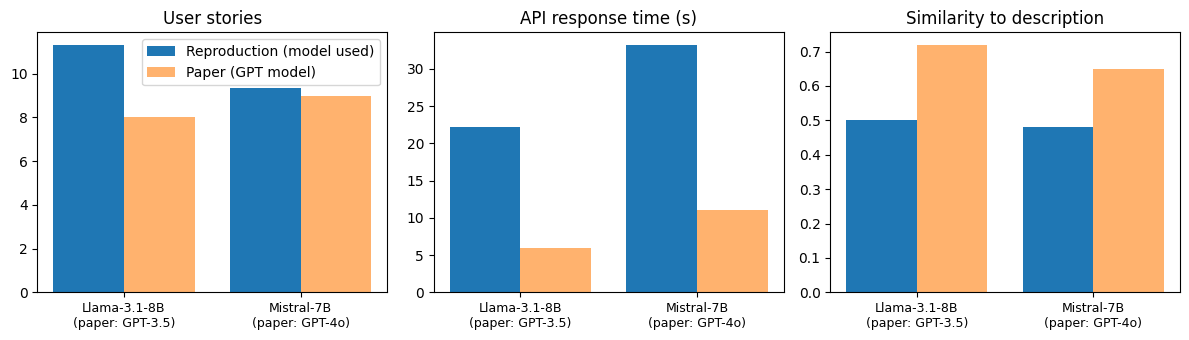

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer, util
st = SentenceTransformer("all-MiniLM-L6-v2")                 # the model used in the paper [8]
desc_emb = st.encode(PROJECT_DESCRIPTION, convert_to_tensor=True)
FORMAT = re.compile(r"^\s*as an? .+?,\s*i want .+", re.I | re.S)

rows = []
for key, g in GEN.items():
    name, r = key.split("|")
    texts = [s["user_story"] for s in g["stories"]]
    sims = util.cos_sim(st.encode(texts, convert_to_tensor=True), desc_emb).cpu().numpy().ravel()
    inv = g["invest_evaluation"]
    crit = ["independent", "negotiable", "valuable", "estimable", "small", "testable"]
    invest_pass = np.mean([all(bool(e.get(c, False)) for c in crit) for e in inv]) if inv else np.nan
    rows.append({"model": name, "run": int(r), "n_stories": len(texts), "response_time_s": g["response_time_s"],
                 "similarity": float(sims.mean()), "format_ok": float(np.mean([bool(FORMAT.match(t)) for t in texts])),
                 "invest_all_criteria": invest_pass})
T_GEN = pd.DataFrame(rows)
FIG3 = T_GEN.groupby("model")[["n_stories", "response_time_s", "similarity", "format_ok", "invest_all_criteria"]].mean().round(2)
FIG3["paper_n_stories"]   = FIG3.index.map({"GPT-3.5": 8, "GPT-4o": 9})
FIG3["paper_time_s"]      = FIG3.index.map({"GPT-3.5": 5.91, "GPT-4o": 11.00})
FIG3["paper_similarity"]  = FIG3.index.map({"GPT-3.5": 0.72, "GPT-4o": 0.65})
display(FIG3.rename(index=NAME))

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for a, (col, paper, label) in zip(ax, [("n_stories", "paper_n_stories", "User stories"),
                                       ("response_time_s", "paper_time_s", "API response time (s)"),
                                       ("similarity", "paper_similarity", "Similarity to description")]):
    x = np.arange(len(FIG3)); a.bar(x - 0.2, FIG3[col], 0.4, label="Reproduction (model used)")
    a.bar(x + 0.2, FIG3[paper], 0.4, label="Paper (GPT model)", alpha=0.6)
    a.set_xticks(x); a.set_xticklabels([NAME[i].replace(" (", "\n(") for i in FIG3.index], fontsize=9); a.set_title(label)
ax[0].legend(); plt.tight_layout(); plt.savefig(OUT / "figure3_reproduction.png", dpi=200); plt.show()

## Step 11 - Evaluation: Table 2 and the optimal (most frequent) prioritization

In [ ]:
from collections import Counter
from scipy.stats import kendalltau
ids = [s["id"] for s in BASE_STORIES]
get = lambda d, i: d[str(i)] if str(i) in d else d[i]      # keys are ints in memory, strings after reloading JSON
optimal = {}
for name in MODELS:
    runs = [PRI[f"{name}|{r}"] for r in range(1, RUNS + 1)]
    orders = [tuple(sorted(ids, key=lambda i: (get(p["rank"], i), i))) for p in runs]
    best, freq = Counter(orders).most_common(1)[0]
    pick = runs[orders.index(best)]
    optimal[name] = {"rank": {i: get(pick["rank"], i) for i in ids}, "dollars": {i: get(pick["dollars"], i) for i in ids},
                     "frequency": f"{freq}/{RUNS}"}
    print(f"{NAME[name]}: optimal ranking chosen in {freq} of {RUNS} runs")

T2 = pd.DataFrame({"Story": [s["story_name"] for s in BASE_STORIES], "User story": [s["user_story"] for s in BASE_STORIES]}, index=ids)
for name in MODELS:
    short = PRETTY.get(MODELS[name], MODELS[name])
    T2[f"{short} Rank"] = [optimal[name]["rank"][i] for i in ids]
    T2[f"{short} $100"] = [optimal[name]["dollars"][i] for i in ids]
pd.set_option("display.max_colwidth", 80); display(T2)

a, b = list(MODELS)
tau = kendalltau([optimal[a]["rank"][i] for i in ids], [optimal[b]["rank"][i] for i in ids])
top2 = {n: set(sorted(ids, key=lambda i: optimal[n]["rank"][i])[:2]) for n in MODELS}
print(f"Agreement between {NAME[a]} and {NAME[b]}: Kendall tau = {tau.statistic:.2f} (p = {tau.pvalue:.3f}); "
      f"shared top-2 stories: {sorted(top2[a] & top2[b])}")
run_tau = {n: np.mean([kendalltau([get(PRI[f"{n}|{x}"]["rank"], i) for i in ids], [get(PRI[f"{n}|{y}"]["rank"], i) for i in ids]).statistic
                       for x in range(1, RUNS + 1) for y in range(x + 1, RUNS + 1)]) for n in MODELS} if RUNS > 1 else {}
print("Run-to-run consistency (mean pairwise Kendall tau):", {NAME[k]: round(float(v), 2) for k, v in run_tau.items()})

Llama-3.1-8B (paper: GPT-3.5): optimal ranking chosen in 2 of 3 runs
Mistral-7B (paper: GPT-4o): optimal ranking chosen in 1 of 3 runs


,Story,User story,Llama-3.1-8B Rank,Llama-3.1-8B $100,Mistral-7B Rank,Mistral-7B $100
1,VendorDataExtraction,"As a data analyst, I want to extract pricing information from PDFs, to/so th...",1,14.9,1,17.1
2,VendorDataTranslation,"As a data analyst, I want to translate extracted data into a structured form...",2,13.4,6,6.0
3,MongoDBDataStorage,"As a data analyst, I want to store vendor data in MongoDB, to/so that I can ...",3,11.2,4,12.8
4,RealTimeAnalysis,"As a procurement manager, I want to enable real-time analysis of vendor data...",3,11.2,3,13.7
5,SupplierComparison,"As a procurement manager, I want to compare pricing information from various...",4,9.0,2,15.4
6,SupplierRecommendation,"As a procurement manager, I want to receive recommendations for the best sup...",4,9.0,5,8.5
7,TotalCostOfProcurement,"As a procurement manager, I want to calculate the total cost of procurement,...",5,7.5,5,8.5
8,IngredientAndCostAnalysis,"As a food manufacturer, I want to analyze ingredient and cost data for speci...",6,6.0,9,2.6
9,SupplierRateComparison,"As a food manufacturer, I want to compare supplier rates for specific produc...",6,6.0,8,4.3
10,RecipeCostCalculation,"As a food manufacturer, I want to calculate the cost of specific recipes, to...",7,4.5,8,4.3


Agreement between Llama-3.1-8B (paper: GPT-3.5) and Mistral-7B (paper: GPT-4o): Kendall tau = 0.60 (p = 0.008); shared top-2 stories: [1]
Run-to-run consistency (mean pairwise Kendall tau): {'Llama-3.1-8B (paper: GPT-3.5)': 0.61, 'Mistral-7B (paper: GPT-4o)': 0.74}


## Step 12 - Save all results (labelled with the real model names) and download

,n_stories,response_time_s,similarity,format_ok,invest_all_criteria,paper_n_stories,paper_time_s,paper_similarity
model,,,,,,,,
Llama-3.1-8B (paper: GPT-3.5),11.33,22.17,0.50,1.00,0.79,8,5.91,0.72
Mistral-7B (paper: GPT-4o),9.33,33.26,0.48,0.67,0.74,9,11.00,0.65


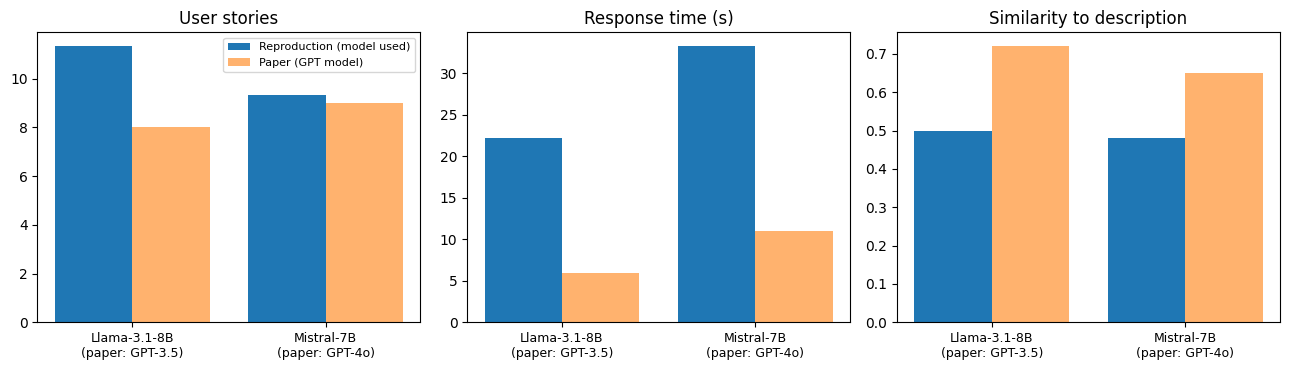

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
FLAT = NAME
LABEL = {k: v.replace(" (", "\n(") for k, v in NAME.items()}
FIG3_named = FIG3.rename(index=FLAT)
T_GEN_named = T_GEN.assign(model=T_GEN["model"].map(FLAT))
T2_named = T2
display(FIG3_named)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, (col, paper, title) in zip(ax, [("n_stories", "paper_n_stories", "User stories"),
                                       ("response_time_s", "paper_time_s", "Response time (s)"),
                                       ("similarity", "paper_similarity", "Similarity to description")]):
    x = np.arange(len(FIG3))
    a.bar(x - 0.2, FIG3[col], 0.4, label="Reproduction (model used)")
    a.bar(x + 0.2, FIG3[paper], 0.4, label="Paper (GPT model)", alpha=0.6)
    a.set_xticks(x); a.set_xticklabels([LABEL[s] for s in FIG3.index], fontsize=9); a.set_title(title)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(OUT / "figure3_reproduction.png", dpi=200); plt.show()

T_GEN_named.to_csv(OUT / "table_generation_runs.csv", index=False)
FIG3_named.to_csv(OUT / "figure3_values.csv")
T2_named.to_csv(OUT / "table2_prioritization.csv")
(OUT / "summary.json").write_text(json.dumps({
    "backend": BACKEND, "models_used": {slot: MODELS[slot] for slot in MODELS},
    "note": "keys are the paper's model slots; values are the models actually run",
    "runs": RUNS, "temperature": TEMPERATURE,
    "figure3": FIG3_named.reset_index().to_dict("records"),
    "optimal_prioritization": {FLAT[n]: {"frequency": o["frequency"], "rank": {str(k): v for k, v in o["rank"].items()},
                                         "dollars": {str(k): v for k, v in o["dollars"].items()}} for n, o in optimal.items()},
    "kendall_tau_between_models": round(float(tau.statistic), 3),
    "run_to_run_tau": {FLAT[k]: round(float(v), 3) for k, v in run_tau.items()}}, indent=1, default=str))
import shutil
shutil.make_archive("/content/profes_results", "zip", OUT)
try:
    from google.colab import files; files.download("/content/profes_results.zip")
except Exception:
    print("Results zipped at /content/profes_results.zip")